# S=7 longer-instruction follow-up (read-only; saved notebook 23b predictions; LAST checkpoint)

No training and no re-evaluation; a CPU runtime is enough.

1. **Causal encoder, S7_k02345, held-out k=7.** Which word structures succeed (a word is typically all-right or
   all-wrong)? Checked features: first/last operation, operation counts, C runs, length after cancelling
   CC/BBBB/AAAAAA, and the shortest word for the overall transform.
2. **Transformer AR, S7_k02345, held-out k=6.** 63% of failures equal "the word with its 5th operation removed".
   Is that unambiguous, and does it depend on the letter / slot of the 5th operation or on the `<identity>` slot?
3. **Causal encoder, S7_k02345, held-out k=6.** Failures concentrate on layouts with `<identity>` in slots 1–3.
   Here they are broken down by number of C tokens and by first operation.

**Send back `S7_LongerK_Followup_Review.ipynb`.**


In [1]:
# --- 2. Bootstrap: locate or clone the PRIVATE repository (credentials are never printed or stored) ---
import base64, importlib.util, os, pathlib, subprocess, sys

REPO_URL = "https://github.com/zhexuandliu/Decompositionality.git"
REPO_BRANCH = "main"
IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ

def _find_repo():
    candidates = [pathlib.Path("/content/Decompositionality"), pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
    for p in candidates:
        if (p / "src" / "decompositionality").is_dir():
            return p.resolve()
    return None

REPO_DIR = _find_repo()
if REPO_DIR is None:
    token = None
    if IN_COLAB:
        try:
            from google.colab import userdata
            token = userdata.get("GITHUB_TOKEN")
        except Exception:
            token = None
    if not token:
        import getpass
        token = getpass.getpass("GitHub token with read access to the private repo (input hidden): ")
    # Pass the credential through environment-scoped git config (not the URL, not the command line,
    # not persisted in .git/config).
    _hdr = "AUTHORIZATION: basic " + base64.b64encode(f"x-access-token:{token}".encode()).decode()
    _env = dict(os.environ, GIT_TERMINAL_PROMPT="0", GIT_CONFIG_COUNT="1",
                GIT_CONFIG_KEY_0="http.https://github.com/.extraheader", GIT_CONFIG_VALUE_0=_hdr)
    REPO_DIR = pathlib.Path("/content/Decompositionality" if IN_COLAB else "Decompositionality").resolve()
    _r = subprocess.run(["git", "clone", "--depth", "1", "--branch", REPO_BRANCH, REPO_URL, str(REPO_DIR)],
                        env=_env, capture_output=True, text=True)
    del token, _hdr, _env
    if _r.returncode != 0:
        raise RuntimeError("git clone failed (check the GITHUB_TOKEN secret / repo access):\n" + _r.stderr[-2000:])

if str(REPO_DIR / "src") not in sys.path:
    sys.path.insert(0, str(REPO_DIR / "src"))
for _mod in ("numpy", "pandas", "matplotlib", "torch"):
    if importlib.util.find_spec(_mod) is None:  # Colab already ships these; never reinstall torch/CUDA here
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", _mod], check=True)
REPO_COMMIT = subprocess.run(["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip()
print("Repository:", REPO_DIR, "| commit:", REPO_COMMIT or "unknown")


Repository: /content/Decompositionality | commit: a54a51b8c8f8c5a6039964165b0e6a2046ef077f


In [2]:
# --- CONFIGURATION -------------------------------------------------------------------------------------------------
MODE = "full"
SEED = 42
SUBDIR = "S7_support_sweep_20k_v1"          # notebook 23a/23b results
USE_DRIVE = IN_COLAB
RESULTS_ROOT = os.environ.get("DECOMP_RESULTS_ROOT") or (
    "/content/drive/MyDrive/decompositionality_results" if USE_DRIVE else str(REPO_DIR / "results"))
# -----------------------------------------------------------------------------------------------------------------
if USE_DRIVE and IN_COLAB and RESULTS_ROOT.startswith("/content/drive"):
    from google.colab import drive
    drive.mount("/content/drive")
import pandas as pd
pd.set_option("display.max_rows", 500); pd.set_option("display.max_columns", 60); pd.set_option("display.width", 250)
from decompositionality import longk_analysis as LA


Mounted at /content/drive


# Follow-up analyses of the S=7 longer-instruction results (read-only; LAST checkpoint)
1. Causal encoder, S7_k02345, k=7: which word structures succeed?
2. Transformer AR, S7_k02345, k=6: which operation is 'dropped'?
3. Causal encoder, S7_k02345, k=6: the early-`<identity>` failures.
All groupings are descriptive (groups differ in other word properties too).


### Sources


,run,status
0,S7_k02345/causal_encoder,ok
1,S7_k02345/transformer_ar,ok



### 1a. Causal encoder k=7: how much each word feature separates success (max − min of group mean word accuracy, groups with ≥ 20 words)


,feature,spread
0,n_A,0.558304
1,max C run,0.487461
2,n_B,0.413128
3,last2,0.383676
4,length after cancelling CC/BBBB/AAAAAA,0.358471
5,first2,0.336168
6,shortest word for the transform,0.291471
7,n_C,0.260896
8,first,0.260280
9,last,0.185505



### 1b. by n_A


... (10 outputs left out)

,value,words,mean_word_acc,always_right,always_wrong
62,1,244,0.376457,52,112
63,3,889,0.395576,226,394
64,5,869,0.515254,290,262
65,7,185,0.667928,81,37



### 1c. Status counts (each word tested on ~9 grids)


,status,words
0,always wrong,805
1,mixed,733
2,always right,649



### Encoder k=7 accuracy vs reduced length


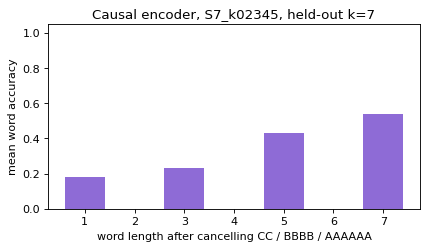


### 2a. Transformer AR k=6 failures: which operation's removal reproduces the prediction (19729 valid failures; 'only' = unambiguous)


,dropped op #,failures where this is the ONLY matching drop,failures matching this drop (incl. ambiguous)
0,1,0,1102
1,2,0,1003
2,3,0,1514
3,4,0,4310
4,5,4631,12512
5,6,0,4404



### 2b. 'Drop op #5' share among AR k=6 failures, by the 5th operation's letter / slot and by the identity slot


,grouping,value,failures,= drop op #5,share
0,letter of op #5,A,6657,6193,0.930
1,letter of op #5,B,6404,110,0.017
2,letter of op #5,C,6668,6209,0.931
3,slot of op #5,5,5628,3576,0.635
4,slot of op #5,6,14101,8936,0.634
5,<identity> slot,1,2785,1783,0.640
6,<identity> slot,2,2796,1775,0.635
7,<identity> slot,3,2818,1776,0.630
8,<identity> slot,4,2826,1793,0.634
9,<identity> slot,5,2876,1809,0.629



### 2c. Reading


,note
0,"drop op #5 = execute ops 1,2,3,4,6 (the last o..."



### 3. Causal encoder k=6: early vs late identity slot, by number of C and by first operation


,layout,grouping,value,records,exact_acc
0,I in slot 1-3,n_C,0,719,0.9722
1,I in slot 1-3,n_C,1,2233,0.9373
2,I in slot 1-3,n_C,2,2799,0.9050
3,I in slot 1-3,n_C,3,1896,0.8539
4,I in slot 1-3,n_C,4,714,0.7577
5,I in slot 1-3,n_C,5,139,0.5468
6,I in slot 1-3,first op,A,2807,0.9049
7,I in slot 1-3,first op,B,2797,0.8509
8,I in slot 1-3,first op,C,2909,0.9089
9,I in slot 4-7,n_C,0,1038,0.9788


REVIEW FILE: /content/drive/MyDrive/decompositionality_results/S7_support_sweep_20k_v1/report/seed_42_longer_k_followup/S7_LongerK_Followup_Review.ipynb
REVIEW FILE TO SEND BACK: /content/drive/MyDrive/decompositionality_results/S7_support_sweep_20k_v1/report/seed_42_longer_k_followup/S7_LongerK_Followup_Review.ipynb


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
# --- Analysis + review export ---------------------------------------------------------------------------------------
rp = LA.followup(RESULTS_ROOT, MODE, SEED, SUBDIR)
print("REVIEW FILE TO SEND BACK:", rp)
if IN_COLAB:
    from google.colab import files
    files.download(str(rp))
